### 03. Условные вероятности: P(высокая оценка | привычка)
Какова вероятность получить > 80 баллов при разных условиях — например, при sleep_hours > 7, study_hours_per_day > 5, mental_health_rating > 7, attendance_percentage > 90? Какой **один** фактор даёт наибольший прирост вероятности? Какой — наименьший?

In [2]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

from src.preparation import load_df
df = load_df()

,base_probability,have_factor_probability,no_factor_probability,base_vs_have_factor_diff
study_5h_plus,27.7,83.8,16.4,67.4
mental_health_7_plus,27.7,40.6,19.7,20.9
sleep_7h_plus,27.7,33.0,24.9,8.1
attendance_pct_90_plus,27.7,31.8,26.1,5.7


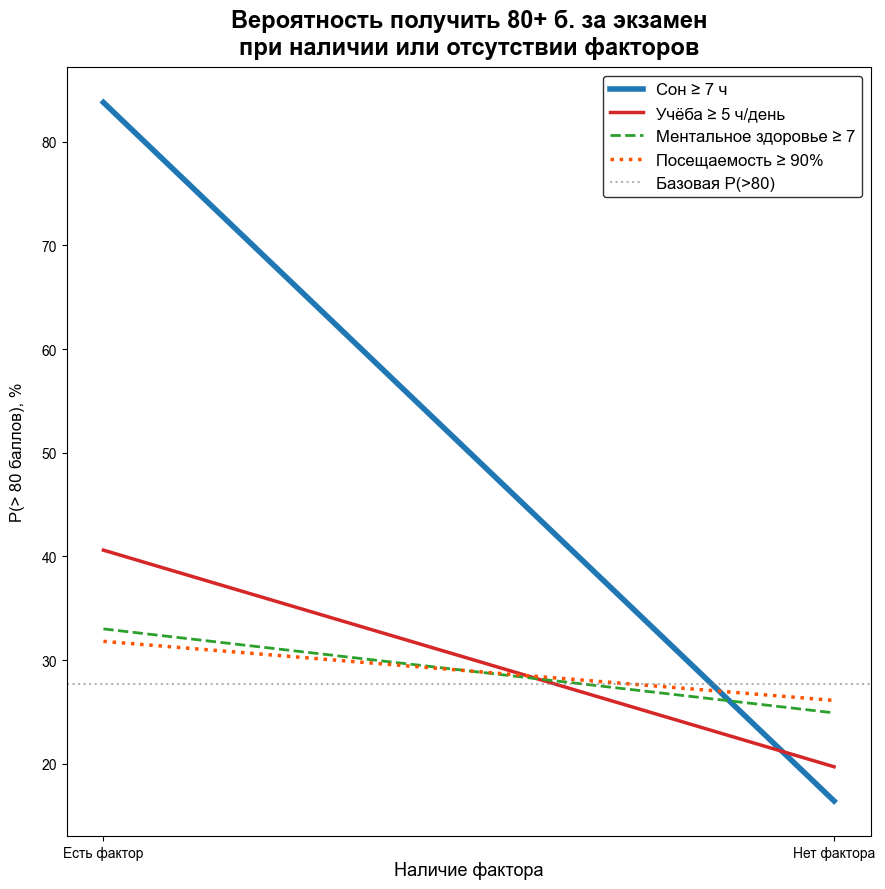

In [11]:
import pandas as pd 
import matplotlib.pyplot as plt 
import src.constants as cnst 

plt.rcParams['font.family'] = 'Arial'

# ! P(A | B) = (P A & B) / P(B)

# определение порога высокой оценки
df.exam_score.min()  # 18.4 
df.exam_score.max()  # 100.0 
df.exam_score.median()  # 70.5 
df.exam_score.mean()  # 69.6015
base_probability = df.loc[df.exam_score >= 80].shape[0] / df.student_id.count()  # 0.277 
# -> Берется порог в 80 баллов, т.к. базовая вероятность P(>80) ≈ 27%. 
# Т.е. примерно каждый четвертый стуеднт получает > 80. 
# Группа достаточно большая, чтобы считать условные вероятности, но и не настолько большая, чтобы >80 баллов перестало быть достижением.

def probability_counter(col_name: str, threshold: int, have_factor: bool = True) -> float:  # ! utils.py 
    if have_factor:
        return df.loc[(df.exam_score >= 80) & (df[col_name] >= threshold)].shape[0] / df.loc[df[col_name] >= threshold].shape[0] * 100
    return df.loc[(df.exam_score >= 80) & (df[col_name] < threshold)].shape[0] / df.loc[df[col_name] < threshold].shape[0] * 100

res_02_03 = pd.DataFrame({
    'base_probability': [base_probability * 100 for _ in range(len(cnst.col_names_thresholds))],
    'have_factor_probability': [probability_counter(col_name, threshold) for col_name, threshold in cnst.col_names_thresholds], 
    'no_factor_probability': [probability_counter(col_name, threshold, False) for col_name, threshold in cnst.col_names_thresholds], 
})

res_02_03.index = ['sleep_7h_plus', 'study_5h_plus', 'mental_health_7_plus', 'attendance_pct_90_plus']
res_02_03 = res_02_03.round(1)
res_02_03['base_vs_have_factor_diff'] = res_02_03.have_factor_probability - res_02_03.no_factor_probability
res_02_03 = res_02_03.sort_values('base_vs_have_factor_diff', ascending=False)

display(res_02_03)


fig, ax = plt.subplots(figsize=(9, 9))

labels = ['Сон ≥ 7 ч', 'Учёба ≥ 5 ч/день', 'Ментальное здоровье ≥ 7', 'Посещаемость ≥ 90%']
linestyles = ['-', '-', '--', ':']
linewidths = [4, 2.5, 2, 2.5]

for i, (label, row) in enumerate(res_02_03[['have_factor_probability', 'no_factor_probability']].iterrows()):
    ax.plot(
        [0, 1], [row.have_factor_probability, row.no_factor_probability], 
        label=labels[i], 
        lw=linewidths[i], color=cnst.group_colors[i], ls=linestyles[i]
    )
    
ax.axhline(base_probability * 100, ls=':', color='gray', alpha=0.6, label='Базовая P(>80)')
    
ax.legend(**cnst.LEGEND_PARAMS)

ax.set_title('Вероятность получить 80+ б. за экзамен\nпри наличии или отсутствии факторов', **cnst.TITLE_PARAMS, fontweight='bold')
ax.set_xticks([0, 1], ['Есть фактор', 'Нет фактора'])
ax.set_xlabel('Наличие фактора', fontsize=13, labelpad=1)
ax.set_ylabel('P(> 80 баллов), %', **cnst.LABEL_PARAMS)

plt.tight_layout()

#### 03. Выводы

После анализа вероятности получить оценку 80+ баллов при разных условиях, были получены следующие выводы:

- ***Учёба ≥ 5 часов*** — доминирующий фактор. Вероятность получить 80+ у таких студентов — **83.8%**, у тех, кто учится меньше — **16.4%**. Разрыв — **67.4 п.п.**

- ***Ментальное здоровье ≥ 7*** — второй по силе фактор. Вероятность **40.6%** против **19.7%**. Разрыв — **20.9 п.п.**

- ***Сон ≥ 7 часов*** и ***посещаемость ≥ 90%*** дают слабый прирост: **33.0%** против **24.9%** (+8.2 п.п.) и **31.8%** против **26.1%** (+5.7 п.п.) соответственно. Эти факторы значительно уступают учёбе и ментальному здоровью.

Базовая вероятность получить > 80 по всей выборке — **27.7%**. Учёба ≥ 5 часов поднимает её до **83.8%**, mental health ≥ 7 — до **40.6%**, сон ≥ 7 — до **33.0%**, посещаемость ≥ 90% — до **31.8%**.